In [9]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    roc_auc_score
)

# Model saving
import joblib

# Paths
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [11]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [13]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [15]:
from pathlib import Path
project_path = Path(
    r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance"
)

processed_path = project_path / "results" / "processed"

print("Processed data folder:", processed_path)

Processed data folder: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\processed


In [17]:

train_df = pd.read_csv(
    processed_path / "train_data.csv"
)

test_df = pd.read_csv(
    processed_path / "test_data.csv"
)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (2710, 12)
Testing dataset shape: (473, 12)


In [19]:
print("TRAINING DATASET")
display(train_df.head())

print("\nTESTING DATASET")
display(test_df.head())

TRAINING DATASET


,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor,Label,Source_File
0,-0.479976,-0.607434,-0.604191,-0.551234,0.625221,-0.623886,-0.625283,-0.401306,-1.250707,-0.603451,0,Normal_1.mat
1,-0.290716,-0.611536,-0.609530,-0.552115,0.626253,-0.623748,-0.625711,-0.388330,-0.865422,-0.574122,0,Normal_1.mat
2,-0.347305,-0.619662,-0.617342,-0.553371,0.626253,-0.623748,-0.625711,-0.378640,-1.209407,-0.516682,0,Normal_1.mat
3,-0.318256,-0.617004,-0.614860,-0.552976,0.636867,-0.623472,-0.630706,-0.402924,-0.678484,-0.532313,0,Normal_1.mat
4,-0.245760,-0.618679,-0.617098,-0.553332,0.638341,-0.619195,-0.629207,-0.403154,-0.752420,-0.464381,0,Normal_1.mat



TESTING DATASET


,Mean,RMS,Standard_Deviation,Variance,Minimum,Maximum,Peak_to_Peak,Kurtosis,Skewness,Crest_Factor,Label,Source_File
0,-0.146767,-0.583318,-0.582047,-0.547378,0.572888,-0.614918,-0.595315,-0.382746,-0.211555,-0.231542,0,Normal_0.mat
1,-0.054269,-0.578554,-0.577948,-0.546629,0.572888,-0.618505,-0.597170,-0.392484,0.728508,-0.266087,0,Normal_0.mat
2,-0.081402,-0.561309,-0.560261,-0.543269,0.605467,-0.611469,-0.609300,-0.401907,0.342435,-0.704299,0,Normal_0.mat
3,-0.134863,-0.565569,-0.564178,-0.544031,0.605467,-0.611469,-0.609300,-0.397223,0.035999,-0.681541,0,Normal_0.mat
4,-0.150608,-0.579199,-0.577849,-0.546611,0.622862,-0.613952,-0.619004,-0.407042,0.994952,-0.659950,0,Normal_0.mat


In [21]:
feature_columns = [
    "Mean",
    "RMS",
    "Standard_Deviation",
    "Variance",
    "Minimum",
    "Maximum",
    "Peak_to_Peak",
    "Kurtosis",
    "Skewness",
    "Crest_Factor"
]

X_train = train_df[feature_columns]
y_train = train_df["Label"]

X_test = test_df[feature_columns]
y_test = test_df["Label"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2710, 10)
y_train: (2710,)
X_test: (473, 10)
y_test: (473,)


In [23]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
Label
0    1887
1     823
Name: count, dtype: int64

Testing class distribution:
Label
0    237
1    236
Name: count, dtype: int64


In [25]:
scaler = joblib.load(
    processed_path / "standard_scaler.pkl"
)

label_encoder = joblib.load(
    processed_path / "label_encoder.pkl"
)

print("Scaler loaded successfully!")
print("Label encoder loaded successfully!")

Scaler loaded successfully!
Label encoder loaded successfully!


Section 4 – Train Logistic Regression









Logistic Regression is our first classification algorithm.

It estimates the probability that a bearing belongs to a particular class.

For example:
- Probability 0.10: likely Normal.
- Probability 0.95: likely Outer Race Fault.

In [28]:
# Cell 9: Create and train the model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [30]:
# make predictions
lr_predictions = lr_model.predict(X_test)

print("First 20 predictions:")
print(lr_predictions[:20])

print("\nActual labels:")
print(y_test.iloc[:20].values)

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Actual labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [32]:
#Evaluate LR
lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

lr_precision = precision_score(
    y_test,
    lr_predictions,
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    lr_predictions,
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    zero_division=0
)

lr_balanced_accuracy = balanced_accuracy_score(
    y_test,
    lr_predictions
)

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)
print("Balanced Accuracy:", lr_balanced_accuracy)

LOGISTIC REGRESSION RESULTS
Accuracy: 0.9957716701902748
Precision: 1.0
Recall: 0.9915254237288136
F1 Score: 0.9957446808510638
Balanced Accuracy: 0.9957627118644068


In [34]:
print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Normal", "Outer Race"]
    )
)

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00       237
  Outer Race       1.00      0.99      1.00       236

    accuracy                           1.00       473
   macro avg       1.00      1.00      1.00       473
weighted avg       1.00      1.00      1.00       473



Section 5 – Train Decision Tree









A Decision Tree makes predictions using a series of conditions.

For example:
Is RMS greater than a threshold?
          |
       YES / NO
          |
    Bearing condition

In [37]:
# Cell 13: Train Decision Tree
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,
    min_samples_split=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [39]:
dt_predictions = dt_model.predict(X_test)

print("First 20 predictions:")
print(dt_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [41]:
dt_accuracy = accuracy_score(
    y_test,
    dt_predictions
)

dt_precision = precision_score(
    y_test,
    dt_predictions,
    zero_division=0
)

dt_recall = recall_score(
    y_test,
    dt_predictions,
    zero_division=0
)

dt_f1 = f1_score(
    y_test,
    dt_predictions,
    zero_division=0
)

dt_balanced_accuracy = balanced_accuracy_score(
    y_test,
    dt_predictions
)

print("DECISION TREE RESULTS")

print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1 Score:", dt_f1)
print("Balanced Accuracy:", dt_balanced_accuracy)

DECISION TREE RESULTS
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Balanced Accuracy: 1.0


Section 6 – Train Random Forest









Random Forest combines multiple Decision Trees and uses their collective predictions.

It is particularly useful for our project because it can learn nonlinear relationships between vibration features and bearing faults.

In [44]:
# Train randomforest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [46]:
rf_predictions = rf_model.predict(X_test)

print("First 20 predictions:")
print(rf_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [48]:
# Evaluate RF
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_precision = precision_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    rf_predictions
)

print("RANDOM FOREST RESULTS")

print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)
print("Balanced Accuracy:", rf_balanced_accuracy)

RANDOM FOREST RESULTS
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Balanced Accuracy: 1.0


Section 7 – Train Support Vector Machine (SVM)









SVM tries to find the optimal boundary separating different classes.

It is particularly useful when features have been standardized, which we have already done.

In [51]:
# Train SVM
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced",
    probability=True,
    random_state=42
)

svm_model.fit(X_train, y_train)

print("SVM training completed!")

SVM training completed!


In [53]:
svm_predictions = svm_model.predict(X_test)

print("First 20 predictions:")
print(svm_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [55]:
svm_accuracy = accuracy_score(
    y_test,
    svm_predictions
)

svm_precision = precision_score(
    y_test,
    svm_predictions,
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_predictions,
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_predictions,
    zero_division=0
)

svm_balanced_accuracy = balanced_accuracy_score(
    y_test,
    svm_predictions
)

print("SVM RESULTS")

print("Accuracy:", svm_accuracy)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1 Score:", svm_f1)
print("Balanced Accuracy:", svm_balanced_accuracy)

SVM RESULTS
Accuracy: 0.9978858350951374
Precision: 1.0
Recall: 0.9957627118644068
F1 Score: 0.9978768577494692
Balanced Accuracy: 0.9978813559322034


Section 8 – Train XGBoost









XGBoost stands for Extreme Gradient Boosting.

It trains decision trees sequentially, with each new tree attempting to correct errors made by previous trees.

It is widely used for structured/tabular data.

In [58]:
# Train XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 2.292831105710814


In [60]:
# now train the model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [62]:
# make predictions
xgb_predictions = xgb_model.predict(X_test)

print("First 20 predictions:")
print(xgb_predictions[:20])

First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [64]:
#Evaluate
xgb_accuracy = accuracy_score(
    y_test,
    xgb_predictions
)

xgb_precision = precision_score(
    y_test,
    xgb_predictions,
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_predictions,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_predictions,
    zero_division=0
)

xgb_balanced_accuracy = balanced_accuracy_score(
    y_test,
    xgb_predictions
)

print("XGBOOST RESULTS")

print("Accuracy:", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1 Score:", xgb_f1)
print("Balanced Accuracy:", xgb_balanced_accuracy)

XGBOOST RESULTS
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Balanced Accuracy: 1.0


#Section 9 – Compare all five models
Now we bring all five models together.

This is where we begin identifying which algorithm performs best for our bearing fault classification problem.
#

In [67]:
#Comparison table
results = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "XGBoost"
    ],

    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy,
        xgb_accuracy
    ],

    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision,
        svm_precision,
        xgb_precision
    ],

    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall,
        svm_recall,
        xgb_recall
    ],

    "F1_Score": [
        lr_f1,
        dt_f1,
        rf_f1,
        svm_f1,
        xgb_f1
    ],

    "Balanced_Accuracy": [
        lr_balanced_accuracy,
        dt_balanced_accuracy,
        rf_balanced_accuracy,
        svm_balanced_accuracy,
        xgb_balanced_accuracy
    ]
}

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1_Score",
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,Balanced_Accuracy
1,Decision Tree,1.0000,1.0,1.0000,1.0000,1.0000
2,Random Forest,1.0000,1.0,1.0000,1.0000,1.0000
4,XGBoost,1.0000,1.0,1.0000,1.0000,1.0000
3,SVM,0.9979,1.0,0.9958,0.9979,0.9979
0,Logistic Regression,0.9958,1.0,0.9915,0.9957,0.9958


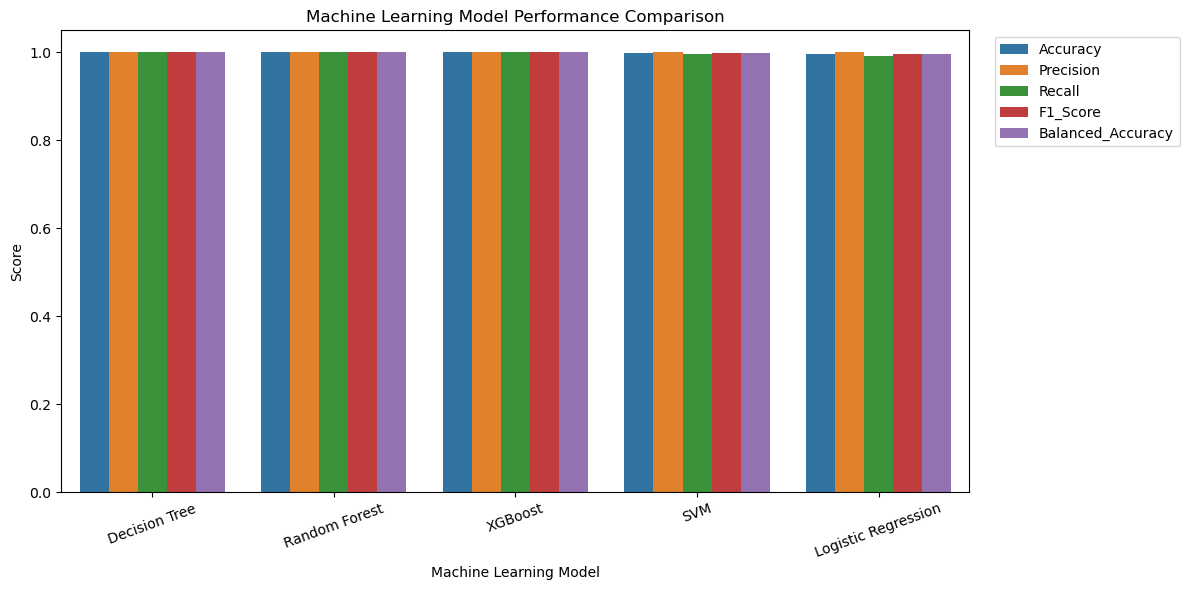

In [69]:
#visualize
plt.figure(figsize=(12, 6))

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score",
        "Balanced_Accuracy"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Performance Comparison")

plt.ylabel("Score")
plt.xlabel("Machine Learning Model")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Section 10 – Confusion Matrix Analysis
A confusion matrix helps us understand exactly how many bearing conditions were predicted correctly and incorrectly.









For our project:
Term	Meaning
True Negative	Normal bearing correctly predicted
True Positive	Outer Race fault correctly predicted
False Positive	Normal bearing incorrectly predicted as faulty
False Negative	Faulty bearing incorrectly predicted as Normal

False Negatives are particularly important because they represent faults our predictive maintenance system failed to detect.

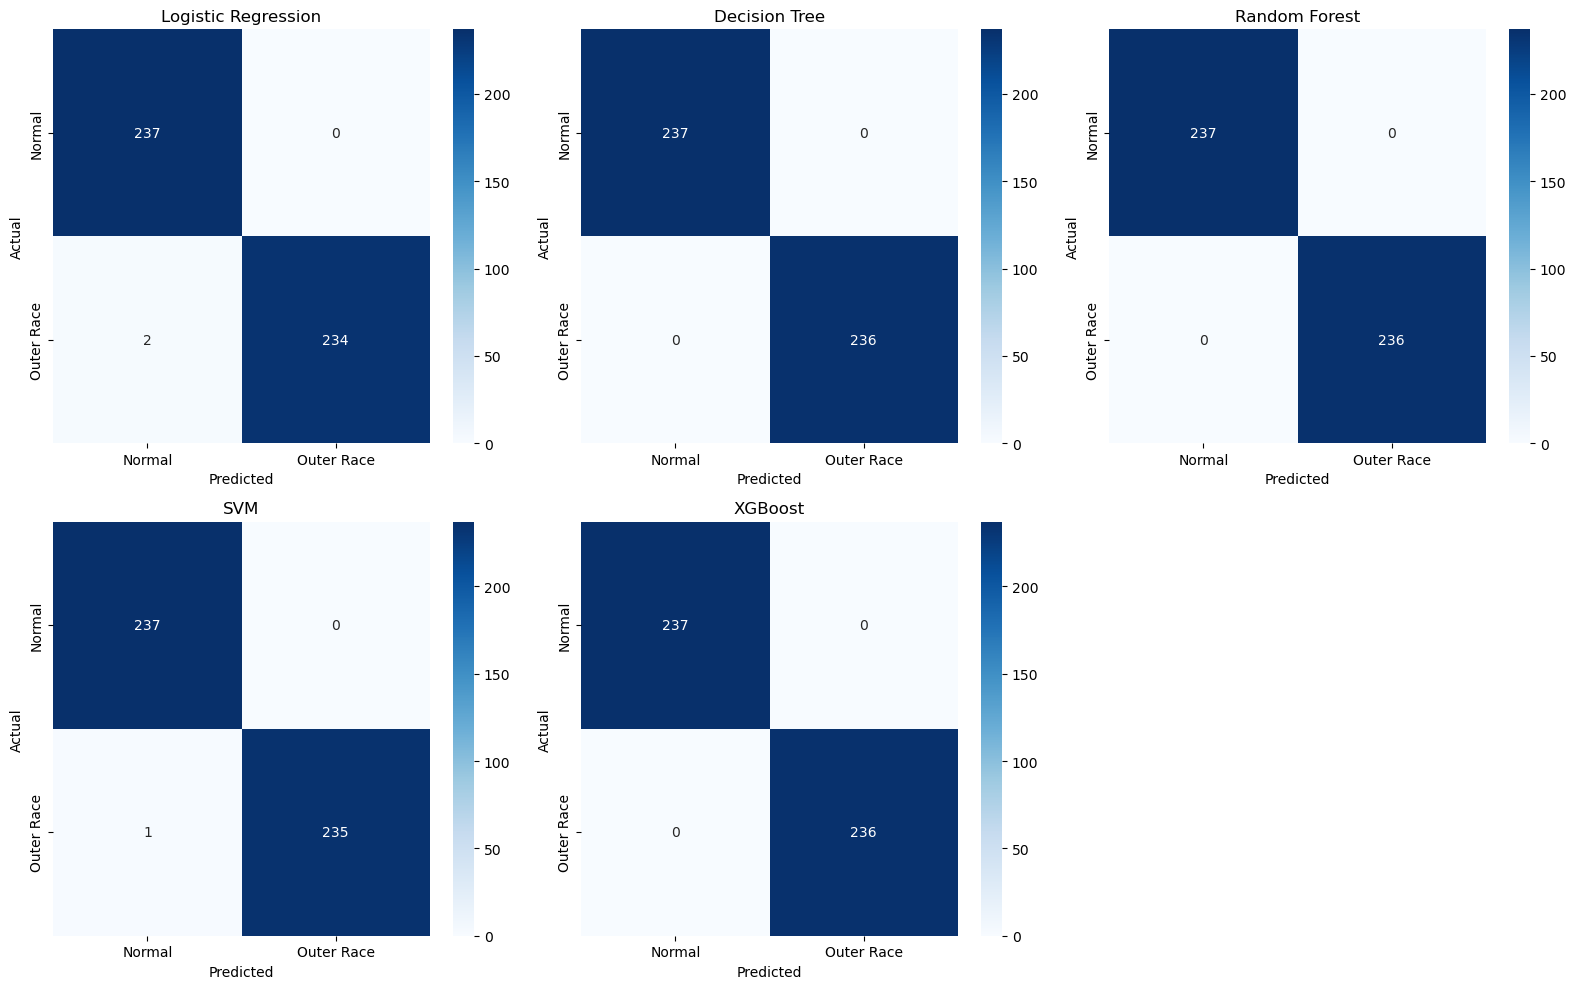

In [72]:
#plot all confusion matrix
models_predictions = {
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "SVM": svm_predictions,
    "XGBoost": xgb_predictions
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (model_name, predictions) in enumerate(
    models_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Outer Race"],
        yticklabels=["Normal", "Outer Race"],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[5].axis("off")

plt.tight_layout()
plt.show()

In [74]:
#detailed report
for model_name, predictions in models_predictions.items():

    print("\n" + "=" * 55)
    print(model_name.upper())
    print("=" * 55)

    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["Normal", "Outer Race"],
            zero_division=0
        )
    )


LOGISTIC REGRESSION
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00       237
  Outer Race       1.00      0.99      1.00       236

    accuracy                           1.00       473
   macro avg       1.00      1.00      1.00       473
weighted avg       1.00      1.00      1.00       473


DECISION TREE
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       237
  Outer Race       1.00      1.00      1.00       236

    accuracy                           1.00       473
   macro avg       1.00      1.00      1.00       473
weighted avg       1.00      1.00      1.00       473


RANDOM FOREST
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       237
  Outer Race       1.00      1.00      1.00       236

    accuracy                           1.00       473
   macro avg       1.00      1.00      1.00       473
weighted avg       1.00

Section 11 – ROC Curve Analysis
ROC curves help us compare how well models distinguish between normal and faulty bearings at different classification thresholds

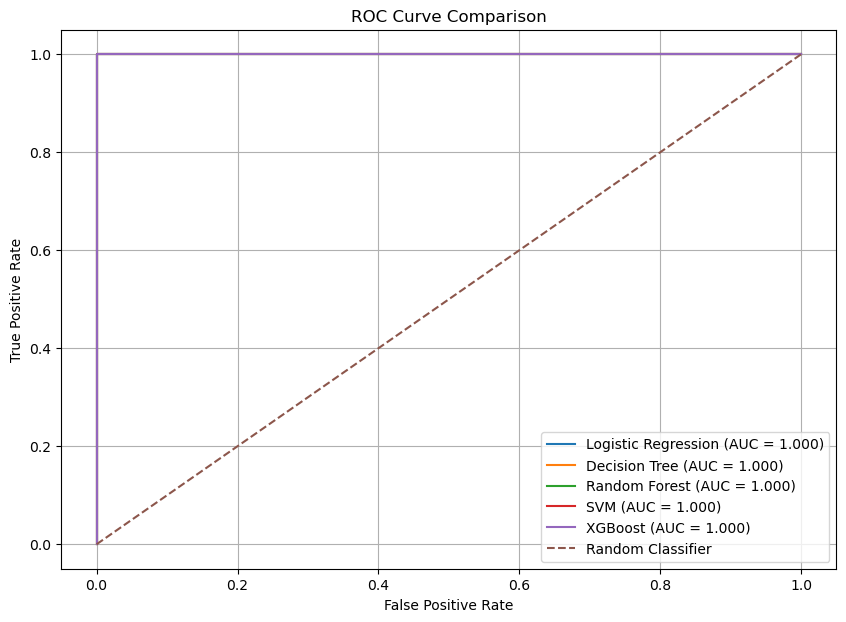

In [77]:
# plot roc curves
from sklearn.metrics import roc_curve, auc

models_probability = {
    "Logistic Regression": lr_model.predict_proba(X_test)[:, 1],
    "Decision Tree": dt_model.predict_proba(X_test)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test)[:, 1],
    "SVM": svm_model.predict_proba(X_test)[:, 1],
    "XGBoost": xgb_model.predict_proba(X_test)[:, 1]
}

plt.figure(figsize=(10, 7))

for model_name, probabilities in models_probability.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

Section 12 – Feature Importance
This section is especially important for becoming an AI Engineer.

We don't just want an AI model that predicts a fault. We also want to understand which vibration characteristics influence its predictions.

For example:
- RMS may indicate vibration energy.
- Kurtosis may indicate impulsive vibration events.
- Peak-to-Peak may indicate vibration amplitude variation.

In [80]:
# Random forest feature importance
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,Standard_Deviation,1.950000e-01
7,Kurtosis,1.650000e-01
5,Maximum,1.550000e-01
6,Peak_to_Peak,1.352389e-01
4,Minimum,1.307895e-01
1,RMS,1.100000e-01
3,Variance,1.050000e-01
9,Crest_Factor,3.971625e-03
0,Mean,4.564835e-15
8,Skewness,4.139186e-15


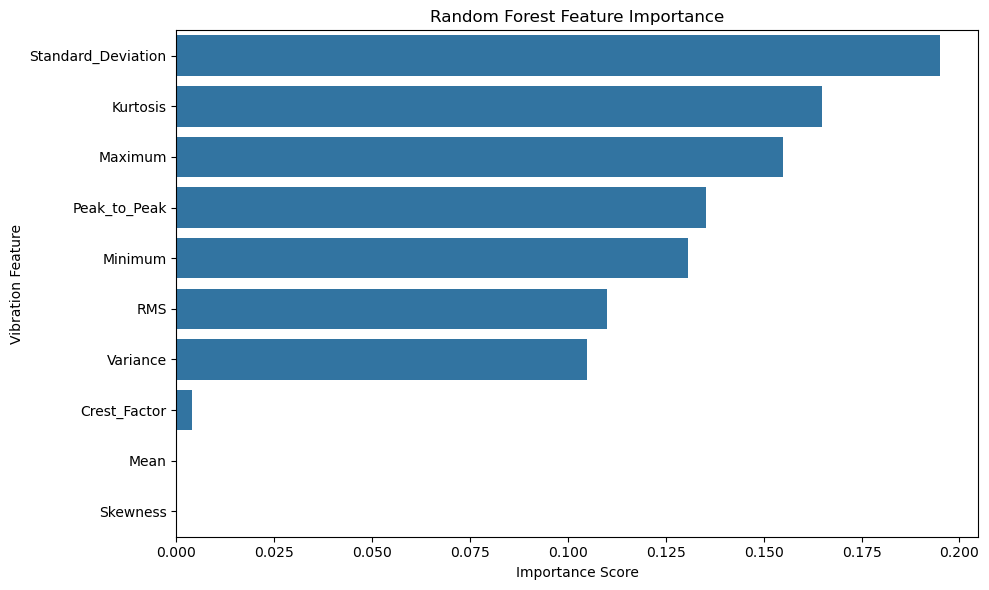

In [82]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance Score")
plt.ylabel("Vibration Feature")

plt.tight_layout()
plt.show()

In [84]:
xgb_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

display(xgb_importance)

,Feature,Importance
7,Kurtosis,0.417881
4,Minimum,0.362423
6,Peak_to_Peak,0.138173
1,RMS,0.069160
2,Standard_Deviation,0.009225
5,Maximum,0.001612
0,Mean,0.001525
3,Variance,0.000000
8,Skewness,0.000000
9,Crest_Factor,0.000000


Section 13 – Select and save the best model
For now, we will select the model with the highest F1-score on our holdout dataset.

This is a preliminary selection, not a final performance claim. Since we have compared several models on the same test set, we should later use group-based cross-validation within the training recordings for model selection and reserve the holdout recordings for final evaluation.

In [87]:
# identify the best performing model
trained_models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "SVM": svm_model,
    "XGBoost": xgb_model
}

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best preliminary model:", best_model_name)

print(
    "F1 Score:",
    results_df.iloc[0]["F1_Score"]
)

Best preliminary model: Decision Tree
F1 Score: 1.0


In [89]:
# save the best model
models_path = project_path / "results" / "models"

models_path.mkdir(
    parents=True,
    exist_ok=True
)

model_file = models_path / "best_bearing_fault_model.pkl"

joblib.dump(
    best_model,
    model_file
)

print("Best model saved successfully!")
print(model_file)

Best model saved successfully!
C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\models\best_bearing_fault_model.pkl


In [91]:
# save model comparison result
results_df.to_csv(
    project_path / "results" / "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    project_path / "results" / "feature_importance.csv",
    index=False
)

print("Model comparison saved!")
print("Feature importance saved!")

Model comparison saved!
Feature importance saved!


In [93]:
print("=" * 60)
print("ELECTRIC MOTOR PREDICTIVE MAINTENANCE")
print("MACHINE LEARNING TRAINING SUMMARY")
print("=" * 60)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModels trained:")

for model_name in trained_models:
    print("-", model_name)

print("\nBest preliminary model:", best_model_name)

print("\nModel performance:")
display(results_df.round(4))

print("\nSaved model:", model_file)

print("\nNotebook 05 execution completed!")

ELECTRIC MOTOR PREDICTIVE MAINTENANCE
MACHINE LEARNING TRAINING SUMMARY

Training samples: 2710
Testing samples: 473

Models trained:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM
- XGBoost

Best preliminary model: Decision Tree

Model performance:


,Model,Accuracy,Precision,Recall,F1_Score,Balanced_Accuracy
1,Decision Tree,1.0000,1.0,1.0000,1.0000,1.0000
2,Random Forest,1.0000,1.0,1.0000,1.0000,1.0000
4,XGBoost,1.0000,1.0,1.0000,1.0000,1.0000
3,SVM,0.9979,1.0,0.9958,0.9979,0.9979
0,Logistic Regression,0.9958,1.0,0.9915,0.9957,0.9958



Saved model: C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\models\best_bearing_fault_model.pkl

Notebook 05 execution completed!


In [95]:
print("dt_model classes:", dt_model.classes_)
print("best_model classes:", best_model.classes_)

print("Are they the same object?", dt_model is best_model)

dt_model classes: [0 1]
best_model classes: [0 1]
Are they the same object? True


In [97]:
print("y_train data type:", y_train.dtype)
print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nUnique labels:")
print(y_train.unique())

y_train data type: int64

Training label distribution:
Label
0    1887
1     823
Name: count, dtype: int64

Unique labels:
[0 1]


In [99]:
print("Model:", dt_model)
print("Classes:", dt_model.classes_)
print("Depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())

print("\nTraining accuracy:",
      dt_model.score(X_train, y_train))

Model: DecisionTreeClassifier(class_weight='balanced', max_depth=8,
                       min_samples_split=10, random_state=42)
Classes: [0 1]
Depth: 2
Number of leaves: 3

Training accuracy: 1.0


In [101]:
train_pred = dt_model.predict(X_train)

print(pd.Series(train_pred).value_counts())

print("\nFirst 20 actual labels:")
print(y_train.head(20).tolist())

print("\nFirst 20 predicted labels:")
print(train_pred[:20])

0    1887
1     823
Name: count, dtype: int64

First 20 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 20 predicted labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [103]:
print("Original model depth:", dt_model.get_depth())
print("Saved model depth:", best_model.get_depth())

print("\nOriginal model leaves:", dt_model.get_n_leaves())
print("Saved model leaves:", best_model.get_n_leaves())

print("\nAre both models identical?")
print(dt_model.tree_.__eq__(best_model.tree_))

Original model depth: 2
Saved model depth: 2

Original model leaves: 3
Saved model leaves: 3

Are both models identical?
True


In [105]:
print("Original model predictions:")
print(pd.Series(dt_model.predict(X_train)).value_counts())

print("\nSaved model predictions:")
print(pd.Series(best_model.predict(X_train)).value_counts())

Original model predictions:
0    1887
1     823
Name: count, dtype: int64

Saved model predictions:
0    1887
1     823
Name: count, dtype: int64


In [107]:
joblib.dump(dt_model, model_file)
print("Correct Decision Tree model saved!")

Correct Decision Tree model saved!


In [109]:
print("Original model depth:", dt_model.get_depth())
print("Saved model depth:", best_model.get_depth())

print("\nOriginal model leaves:", dt_model.get_n_leaves())
print("Saved model leaves:", best_model.get_n_leaves())

print("\nOriginal model predictions:")
print(pd.Series(dt_model.predict(X_train)).value_counts())

print("\nSaved model predictions:")
print(pd.Series(best_model.predict(X_train)).value_counts())

Original model depth: 2
Saved model depth: 2

Original model leaves: 3
Saved model leaves: 3

Original model predictions:
0    1887
1     823
Name: count, dtype: int64

Saved model predictions:
0    1887
1     823
Name: count, dtype: int64


In [111]:
print("Notebook 05 training shape:", X_train.shape)

print("\nFirst 5 training rows:")
print(X_train.head())

print("\nTraining feature means:")
print(X_train.mean())

Notebook 05 training shape: (2710, 10)

First 5 training rows:
       Mean       RMS  Standard_Deviation  Variance   Minimum   Maximum  \
0 -0.479976 -0.607434           -0.604191 -0.551234  0.625221 -0.623886   
1 -0.290716 -0.611536           -0.609530 -0.552115  0.626253 -0.623748   
2 -0.347305 -0.619662           -0.617342 -0.553371  0.626253 -0.623748   
3 -0.318256 -0.617004           -0.614860 -0.552976  0.636867 -0.623472   
4 -0.245760 -0.618679           -0.617098 -0.553332  0.638341 -0.619195   

   Peak_to_Peak  Kurtosis  Skewness  Crest_Factor  
0     -0.625283 -0.401306 -1.250707     -0.603451  
1     -0.625711 -0.388330 -0.865422     -0.574122  
2     -0.625711 -0.378640 -1.209407     -0.516682  
3     -0.630706 -0.402924 -0.678484     -0.532313  
4     -0.629207 -0.403154 -0.752420     -0.464381  

Training feature means:
Mean                  1.678035e-16
RMS                   8.390173e-17
Standard_Deviation   -2.097543e-16
Variance              0.000000e+00
Minimum  

In [113]:
print("ORIGINAL MODEL")
print("Tree features:", dt_model.tree_.feature)
print("Tree thresholds:", dt_model.tree_.threshold)
print("Tree values:")
print(dt_model.tree_.value)

ORIGINAL MODEL
Tree features: [ 4 -2  2 -2 -2]
Tree thresholds: [ 0.17840053 -2.         -0.63364783 -2.         -2.        ]
Tree values:
[[[0.5 0.5]]

 [[0.  1. ]]

 [[1.  0. ]]

 [[1.  0. ]]

 [[1.  0. ]]]


In [115]:
print("Notebook 05:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nFirst 10 Minimum values:")
print(X_train["Minimum"].head(10).tolist())

print("\nFirst 10 labels:")
print(y_train.head(10).tolist())

print("\nIndex alignment:")
print(X_train.index.equals(y_train.index))

Notebook 05:
X_train shape: (2710, 10)
y_train shape: (2710,)

First 10 Minimum values:
[0.6252208379107076, 0.6262527463354297, 0.6262527463354297, 0.6368666615611422, 0.6383408164536023, 0.6352450911794362, 0.6266949928031678, 0.6266949928031678, 0.6047300849055124, 0.6047300849055124]

First 10 labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Index alignment:
True


In [117]:
print("Notebook 05 feature statistics:")
print(X_train[["Mean", "RMS", "Minimum", "Maximum"]].describe())

Notebook 05 feature statistics:
               Mean           RMS       Minimum      Maximum
count  2.710000e+03  2.710000e+03  2.710000e+03  2710.000000
mean   1.678035e-16  8.390173e-17  8.390173e-17     0.000000
std    1.000185e+00  1.000185e+00  1.000185e+00     1.000185
min   -9.319672e-01 -6.346842e-01 -3.765056e+00    -0.654928
25%   -3.796589e-01 -6.155276e-01 -1.141408e+00    -0.627887
50%   -1.617497e-01 -6.075595e-01  6.134276e-01    -0.615815
75%    3.787662e-02  5.531490e-01  6.266950e-01     1.073421
max    6.629997e+00  2.466663e+00  6.588316e-01     3.640838


In [119]:
print("Scaler exists:", "scaler" in globals())

if "scaler" in globals():
    print(type(scaler))
    print("Number of features:", scaler.n_features_in_)

Scaler exists: True
<class 'sklearn.preprocessing._data.StandardScaler'>
Number of features: 10


In [121]:
import joblib

scaler_file = models_path / "bearing_feature_scaler.pkl"

joblib.dump(scaler, scaler_file)

print("Scaler saved successfully!")
print(scaler_file)

Scaler saved successfully!
C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\results\models\bearing_feature_scaler.pkl


In [1]:
import sklearn
import pandas
import numpy
import joblib

print("Scikit-learn:", sklearn.__version__)
print("Pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("Joblib:", joblib.__version__)

Scikit-learn: 1.5.1
Pandas: 2.2.2
NumPy: 1.26.4
Joblib: 1.4.2
